In [2]:
import sys
!{sys.executable} -m pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable


In [1]:
pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
from sklearn.datasets import fetch_olivetti_faces

# ---- seed from roll number ----
roll = "P26CS0011"
digits = [int(c) for c in roll if c.isdigit()]   # [2,6,0,0,1,1]
rng = np.random.default_rng(digits)

# ---- load data ----
data = fetch_olivetti_faces()
X = data.data            # (400, 4096) flattened pixels
y = data.target          # (400,) labels 0..39

# ---- per-identity split: 6 / 2 / 2 ----
train_idx, val_idx, test_idx = [], [], []
for k in range(40):
    idx = rng.permutation(np.where(y == k)[0])
    train_idx += list(idx[:6])
    val_idx   += list(idx[6:8])
    test_idx  += list(idx[8:])

train_idx, val_idx, test_idx = map(np.array, (train_idx, val_idx, test_idx))
np.savez("split.npz", train=train_idx, val=val_idx, test=test_idx)

X_train, y_train = X[train_idx], y[train_idx]
X_val,   y_val   = X[val_idx],   y[val_idx]
X_test,  y_test  = X[test_idx],  y[test_idx]

# ---- masked test set (centre 16x16 block = 0) ----
X_test_masked = X_test.copy().reshape(-1, 64, 64)
X_test_masked[:, 24:40, 24:40] = 0
X_test_masked = X_test_masked.reshape(-1, 4096)

print(X_train.shape, X_val.shape, X_test.shape, X_test_masked.shape)
# expected: (240, 4096) (80, 4096) (80, 4096) (80, 4096)

(240, 4096) (80, 4096) (80, 4096) (80, 4096)


In [4]:
from sklearn.tree import DecisionTreeClassifier
import pandas as pd

depths = [2, 4, 8, 16, None]
leaves_opts = [1, 2, 4]

def leaf_stats(tree):
    t = tree.tree_
    is_leaf = t.children_left == -1
    n_leaves = is_leaf.sum()
    samples = t.n_node_samples[is_leaf]
    return n_leaves, samples.mean(), (samples == 1).mean()

rows = []
for d in depths:
    for m in leaves_opts:
        clf = DecisionTreeClassifier(max_depth=d, min_samples_leaf=m, random_state=0)
        clf.fit(X_train, y_train)
        n_leaves, mean_s, frac1 = leaf_stats(clf)
        rows.append({
            "depth": d, "min_leaf": m,
            "train": clf.score(X_train, y_train),
            "val": clf.score(X_val, y_val),
            "leaves": n_leaves, "mean_samples": mean_s, "frac_single": frac1,
        })

grid = pd.DataFrame(rows)
print(grid.round(3).to_string())

# ---- selection by validation accuracy only ----
# tie-break: smaller depth first (None = largest), then larger min_leaf
grid["depth_key"] = grid["depth"].apply(lambda d: 10**9 if d is None or pd.isna(d) else d)
best = grid.sort_values(["val", "depth_key", "min_leaf"],
                        ascending=[False, True, False]).iloc[0]
best_depth = None if pd.isna(best["depth"]) else int(best["depth"])
best_leaf = int(best["min_leaf"])
print("Selected:", best_depth, best_leaf)

# ---- freeze ----
tree_cfg = dict(max_depth=best_depth, min_samples_leaf=best_leaf, random_state=0)
tree = DecisionTreeClassifier(**tree_cfg).fit(X_train, y_train)

n_leaves, mean_s, frac1 = leaf_stats(tree)
print("train", tree.score(X_train, y_train))
print("val  ", tree.score(X_val, y_val))
print("test ", tree.score(X_test, y_test))
print("leaves", n_leaves, "| mean samples/leaf", round(mean_s, 2),
      "| frac single-sample leaves", round(frac1, 3))

    depth  min_leaf  train    val  leaves  mean_samples  frac_single
0     2.0         1  0.075  0.062       3        80.000        0.000
1     2.0         2  0.075  0.062       3        80.000        0.000
2     2.0         4  0.075  0.062       3        80.000        0.000
3     4.0         1  0.125  0.112       5        48.000        0.000
4     4.0         2  0.125  0.112       5        48.000        0.000
5     4.0         4  0.125  0.112       5        48.000        0.000
6     8.0         1  0.225  0.188       9        26.667        0.000
7     8.0         2  0.225  0.188       9        26.667        0.000
8     8.0         4  0.225  0.188       9        26.667        0.000
9    16.0         1  0.425  0.288      17        14.118        0.000
10   16.0         2  0.425  0.288      17        14.118        0.000
11   16.0         4  0.425  0.288      17        14.118        0.000
12    NaN         1  1.000  0.550      44         5.455        0.091
13    NaN         2  0.983  0.550 

     B  train    val   test  avg_distinct   theory  oob_acc  oob_coverage  disagree  margin
0    1  0.750  0.400  0.438        155.00  151.893    0.388         0.354       NaN   1.000
1    5  0.958  0.525  0.525        150.00  151.893    0.384         0.879     0.795   0.235
2   10  0.992  0.625  0.688        150.80  151.893    0.483         0.992     0.814   0.216
3   25  1.000  0.800  0.788        150.52  151.893    0.621         1.000     0.805   0.245
4   50  1.000  0.838  0.888        151.26  151.893    0.700         1.000     0.811   0.252
5  100  1.000  0.838  0.900        152.06  151.893    0.788         1.000     0.794   0.273
6  200  1.000  0.838  0.862        152.30  151.893    0.812         1.000     0.796   0.271


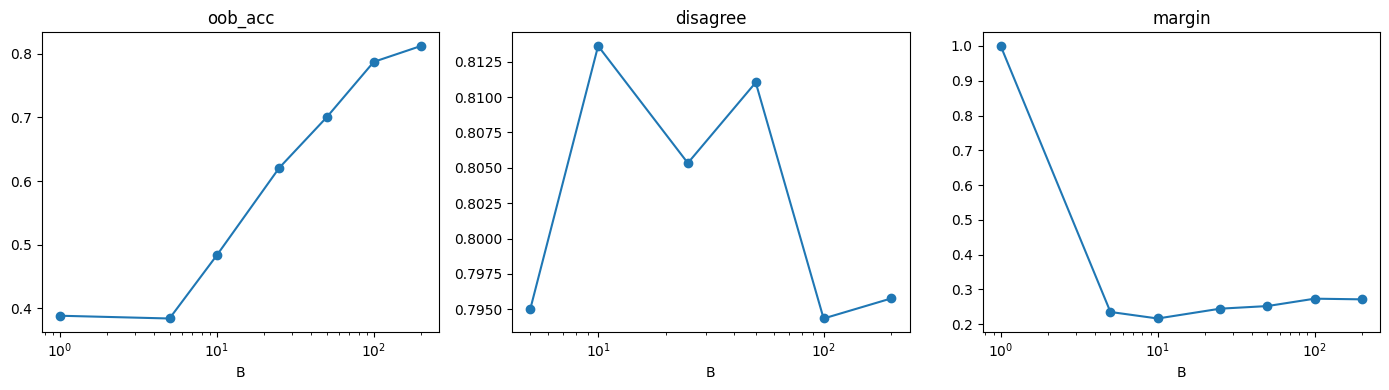

B_final = 50


In [8]:
import matplotlib.pyplot as plt

K, T, N = 40, 200, len(X_train)
Bs = [1, 5, 10, 25, 50, 100, 200]
rng_bag = np.random.default_rng(digits)

trees, inbag, distinct = [], np.zeros((T, N), dtype=bool), []
for t in range(T):
    idx = rng_bag.integers(0, N, size=N)          # bootstrap, size N
    inbag[t, np.unique(idx)] = True
    distinct.append(len(np.unique(idx)))
    m = DecisionTreeClassifier(**{**tree_cfg, "random_state": t})
    trees.append(m.fit(X_train[idx], y_train[idx]))

# predictions of every tree on every set: shape (T, n)
P = {name: np.array([m.predict(Xs) for m in trees])
     for name, Xs in [("train", X_train), ("val", X_val),
                      ("test", X_test), ("mask", X_test_masked)]}

def votes(Pset, B):
    n = Pset.shape[1]
    C = np.zeros((n, K))
    for t in range(B):
        C[np.arange(n), Pset[t]] += 1
    return C                                       # vote counts

def acc(C, yy):
    return (C.argmax(1) == yy).mean()              # ties -> lowest class id

def oob_acc(B):
    C = np.zeros((N, K))
    for t in range(B):
        o = ~inbag[t]
        C[np.where(o)[0], P["train"][t][o]] += 1
    has = C.sum(1) > 0                             # samples with >=1 OOB tree
    return (C.argmax(1)[has] == y_train[has]).mean(), has.mean()

def disagreement(C, B):
    if B == 1: return np.nan
    agree = (C * (C - 1) / 2).sum(1)               # agreeing pairs per sample
    return (1 - agree / (B * (B - 1) / 2)).mean()

def margin(C, B):
    s = np.sort(C, axis=1)
    return ((s[:, -1] - s[:, -2]) / B).mean()

theory = N * (1 - (1 - 1 / N) ** N)
rows = []
for B in Bs:
    Ctr, Cva, Cte = (votes(P[s], B) for s in ("train", "val", "test"))
    oa, cov = oob_acc(B)
    rows.append({"B": B,
        "train": acc(Ctr, y_train), "val": acc(Cva, y_val), "test": acc(Cte, y_test),
        "avg_distinct": np.mean(distinct[:B]), "theory": theory,
        "oob_acc": oa, "oob_coverage": cov,
        "disagree": disagreement(Cva, B), "margin": margin(Cva, B)})
res = pd.DataFrame(rows)
print(res.round(3).to_string())

# plots: OOB acc, disagreement, margin vs B
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, col in zip(ax, ["oob_acc", "disagree", "margin"]):
    a.plot(res["B"], res[col], marker="o"); a.set_xscale("log")
    a.set_xlabel("B"); a.set_title(col)
plt.tight_layout(); plt.savefig("q1c_plots.png", dpi=150); plt.show()

# final B: best val accuracy (tie -> smaller B)
best_row = res.sort_values(["val", "B"], ascending=[False, True]).iloc[0]
B_final = int(best_row["B"]); print("B_final =", B_final)

  model  clean_acc  mask_acc  clean_conf  mask_conf
   tree      0.600     0.275       0.994      0.975
bagging      0.888     0.675       0.378      0.248
Bagging corrects tree:
test idx 1 | true 0 | tree pred 7 | bag pred 0 | bag top votes [(0, 18), (17, 6), (15, 6)] | true-class votes 18
test idx 9 | true 4 | tree pred 30 | bag pred 4 | bag top votes [(4, 14), (11, 6), (16, 5)] | true-class votes 14
Both wrong:
test idx 6 | true 3 | tree pred 0 | bag pred 39 | bag top votes [(39, 8), (16, 7), (0, 5)] | true-class votes 2
test idx 17 | true 8 | tree pred 3 | bag pred 12 | bag top votes [(12, 5), (34, 4), (20, 4)] | true-class votes 1


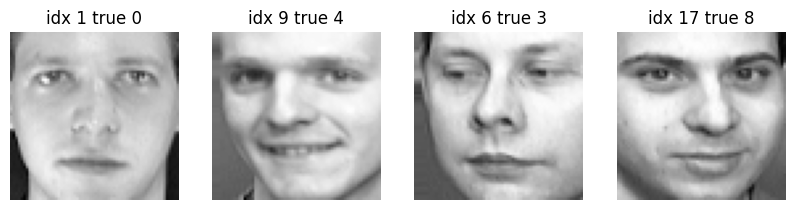

In [9]:
B_final = 50

def bag_eval(Pset, B=B_final):
    C = votes(Pset, B)
    return C, C.argmax(1), C.max(1) / B          # counts, preds, win fraction

tree_clean_pred = tree.predict(X_test)
tree_mask_pred  = tree.predict(X_test_masked)
tree_clean_conf = tree.predict_proba(X_test).max(1)
tree_mask_conf  = tree.predict_proba(X_test_masked).max(1)

Cc, bag_clean_pred, bag_clean_conf = bag_eval(P["test"])
Cm, bag_mask_pred,  bag_mask_conf  = bag_eval(P["mask"])

summary = pd.DataFrame({
    "model": ["tree", "bagging"],
    "clean_acc": [(tree_clean_pred == y_test).mean(), (bag_clean_pred == y_test).mean()],
    "mask_acc":  [(tree_mask_pred == y_test).mean(),  (bag_mask_pred == y_test).mean()],
    "clean_conf": [tree_clean_conf.mean(), bag_clean_conf.mean()],
    "mask_conf":  [tree_mask_conf.mean(),  bag_mask_conf.mean()],
})
print(summary.round(3).to_string(index=False))

def show(i):
    top = np.argsort(Cc[i])[::-1][:3]
    print(f"test idx {i} | true {y_test[i]} | tree pred {tree_clean_pred[i]} "
          f"| bag pred {bag_clean_pred[i]} | bag top votes "
          f"{[(int(k), int(Cc[i][k])) for k in top]} "
          f"| true-class votes {int(Cc[i][y_test[i]])}")

fixed = np.where((tree_clean_pred != y_test) & (bag_clean_pred == y_test))[0][:2]
both_wrong = np.where((tree_clean_pred != y_test) & (bag_clean_pred != y_test))[0][:2]
print("Bagging corrects tree:");  [show(i) for i in fixed]
print("Both wrong:");             [show(i) for i in both_wrong]

# optional: view these faces
sel = list(fixed) + list(both_wrong)
fig, ax = plt.subplots(1, 4, figsize=(10, 3))
for a, i in zip(ax, sel):
    a.imshow(X_test[i].reshape(64, 64), cmap="gray"); a.axis("off")
    a.set_title(f"idx {i} true {y_test[i]}")
plt.savefig("q1d_faces.png", dpi=150); plt.show()

Q2 -

In [10]:
from math import log

def samme_round(X, y, w, K, depth=1, seed=0):
    """One SAMME round. Returns (learner, pred, eps, alpha, new_w) or None."""
    h = DecisionTreeClassifier(max_depth=depth, random_state=seed)
    h.fit(X, y, sample_weight=w)
    pred = h.predict(X)
    miss = pred != y
    eps = w[miss].sum() / w.sum()
    if eps >= 1 - 1.0 / K:            # not better than random guessing
        return None
    eps = max(eps, 1e-10)             # avoid log(0) for a perfect learner
    alpha = log((1 - eps) / eps) + log(K - 1)
    new_w = w * np.exp(alpha * miss)
    new_w /= new_w.sum()
    return h, pred, eps, alpha, new_w

# ---- toy data: 3 classes, 9 samples ----
X_toy = np.array([[1,1],[1,2],[2,1],
                  [4,1],[5,2],[4,3],
                  [2,5],[3,5],[3,4]], dtype=float)
y_toy = np.array([0,0,0, 1,1,1, 2,2,2])
K_toy = 3
w0 = np.ones(len(y_toy)) / len(y_toy)

out = samme_round(X_toy, y_toy, w0, K_toy, depth=1)
if out is None:
    print("weak learner rejected")
else:
    h, pred, eps, alpha, w1 = out
    log_df = pd.DataFrame({"x1": X_toy[:,0], "x2": X_toy[:,1], "y": y_toy,
                           "w_init": w0, "pred": pred,
                           "wrong": pred != y_toy, "w_new": w1})
    print(log_df.round(4).to_string())
    print("eps =", round(eps, 4), "| alpha =", round(alpha, 4))
    print("weights sum:", w1.sum().round(6))
    print("total weight of misclassified after update:", w1[pred != y_toy].sum().round(4))

    x1   x2  y  w_init  pred  wrong   w_new
0  1.0  1.0  0  0.1111     0  False  0.0556
1  1.0  2.0  0  0.1111     0  False  0.0556
2  2.0  1.0  0  0.1111     0  False  0.0556
3  4.0  1.0  1  0.1111     0   True  0.2222
4  5.0  2.0  1  0.1111     0   True  0.2222
5  4.0  3.0  1  0.1111     0   True  0.2222
6  2.0  5.0  2  0.1111     2  False  0.0556
7  3.0  5.0  2  0.1111     2  False  0.0556
8  3.0  4.0  2  0.1111     2  False  0.0556
eps = 0.3333 | alpha = 1.3863
weights sum: 1.0
total weight of misclassified after update: 0.6667


    depth  rounds  rounds_used  train    val
0       1      10           10  0.050  0.050
1       1      25           25  0.050  0.038
2       1      50           50  0.096  0.050
3       1     100          100  0.212  0.100
4       2      10           10  0.117  0.088
5       2      25           25  0.171  0.112
6       2      50           50  0.354  0.200
7       2     100          100  0.250  0.062
8       3      10           10  0.233  0.138
9       3      25           25  0.296  0.125
10      3      50           50  0.704  0.300
11      3     100          100  0.658  0.250
12      4      10           10  0.296  0.125
13      4      25           25  0.446  0.150
14      4      50           50  0.771  0.300
15      4     100          100  0.683  0.238
Selected boosting: depth 3 rounds 50
round-1 misclassified weight after update: 0.975 | expected 0.975


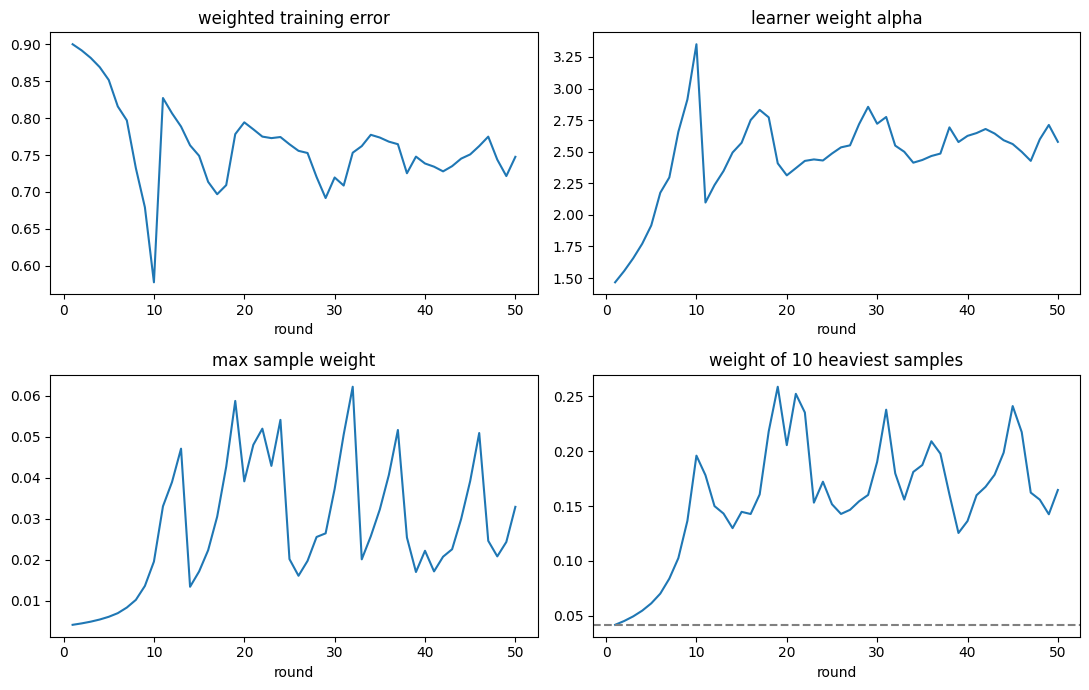

In [11]:
K = 40
depths_b = [1, 2, 3, 4]
rounds_b = [10, 25, 50, 100]
T_max = max(rounds_b)

def samme_fit(X, y, K, depth, T, seed=0):
    N = len(y)
    w = np.ones(N) / N
    m = dict(learners=[], alphas=[], eps=[], W=[], train_pred=[], depth=depth)
    for t in range(T):
        out = samme_round(X, y, w, K, depth, seed + t)
        if out is None:                       # not better than random guessing
            print(f"depth {depth}: learner rejected at round {t+1}, stopping")
            break
        h, pred, eps, alpha, new_w = out
        m["learners"].append(h); m["alphas"].append(alpha); m["eps"].append(eps)
        m["W"].append(w.copy())               # weights used in this round
        m["train_pred"].append(pred)
        w = new_w
    m["alphas"] = np.array(m["alphas"])
    return m

def samme_scores(m, Xs, R):
    n = len(Xs)
    S = np.zeros((n, K))
    for h, a in zip(m["learners"][:R], m["alphas"][:R]):
        S[np.arange(n), h.predict(Xs)] += a
    return S

def samme_proba(m, Xs, R):
    S = samme_scores(m, Xs, R)
    return S / m["alphas"][:R].sum()          # q_k(x)

boost_models, rows = {}, []
for d in depths_b:
    m = samme_fit(X_train, y_train, K, d, T_max)
    boost_models[d] = m
    for R in rounds_b:
        R_eff = min(R, len(m["alphas"]))
        rows.append({"depth": d, "rounds": R, "rounds_used": R_eff,
                     "train": (samme_proba(m, X_train, R_eff).argmax(1) == y_train).mean(),
                     "val":   (samme_proba(m, X_val,   R_eff).argmax(1) == y_val).mean()})
bgrid = pd.DataFrame(rows)
print(bgrid.round(3).to_string())

# select on clean validation only; tie -> smaller depth, then fewer rounds
bbest = bgrid.sort_values(["val", "depth", "rounds"], ascending=[False, True, True]).iloc[0]
b_depth, b_rounds = int(bbest["depth"]), int(bbest["rounds_used"])
print("Selected boosting: depth", b_depth, "rounds", b_rounds)

# ---- sanity check: misclassified weight after update should be (K-1)/K ----
m = boost_models[b_depth]
mis1 = m["train_pred"][0] != y_train
print("round-1 misclassified weight after update:", round(m["W"][1][mis1].sum(), 4),
      "| expected", (K - 1) / K)

# ---- plots for selected model ----
Rb = b_rounds
rr = np.arange(1, Rb + 1)
Wm = np.array(m["W"][:Rb])                    # (Rb, N)
top10 = np.sort(Wm, axis=1)[:, -10:].sum(1)

fig, ax = plt.subplots(2, 2, figsize=(11, 7))
ax[0,0].plot(rr, m["eps"][:Rb]);   ax[0,0].set_title("weighted training error")
ax[0,1].plot(rr, m["alphas"][:Rb]); ax[0,1].set_title("learner weight alpha")
ax[1,0].plot(rr, Wm.max(1));       ax[1,0].set_title("max sample weight")
ax[1,1].plot(rr, top10);           ax[1,1].set_title("weight of 10 heaviest samples")
ax[1,1].axhline(10 / len(y_train), ls="--", c="gray")   # uniform baseline
for a in ax.ravel(): a.set_xlabel("round")
plt.tight_layout(); plt.savefig("q2b_plots.png", dpi=150); plt.show()

       model   L  train   val  test  time_s
     bagging  25  1.000 0.800 0.788  14.862
boosting d=3  25  0.296 0.125 0.125   3.700
     bagging  50  1.000 0.838 0.888  29.612
boosting d=3  50  0.704 0.300 0.312   7.137
     bagging 100  1.000 0.838 0.900  59.809
boosting d=3 100  0.658 0.250 0.238  13.907
heavy face idx 236 | true class 39
max weight 0.0623 | uniform 0.0042
learners right: 5 of 50 | average over all faces: 5.4
most common wrong predictions:
 2    5
4    5
3    5
Name: count, dtype: int64
final q(true class) = 0.102 | final pred 39
 round  weight  pred  correct    eps  ratio_next  ratio_expected
     1  0.0042     0    False 0.9000      1.0833          1.0833
     2  0.0045     1    False 0.8917      1.0935          1.0935
     3  0.0049     2    False 0.8815      1.1060          1.1060
     4  0.0055     3    False 0.8690      1.1220          1.1220
     5  0.0061     4    False 0.8516      1.1449          1.1449
     6  0.0070    11    False 0.8158      1.1951       

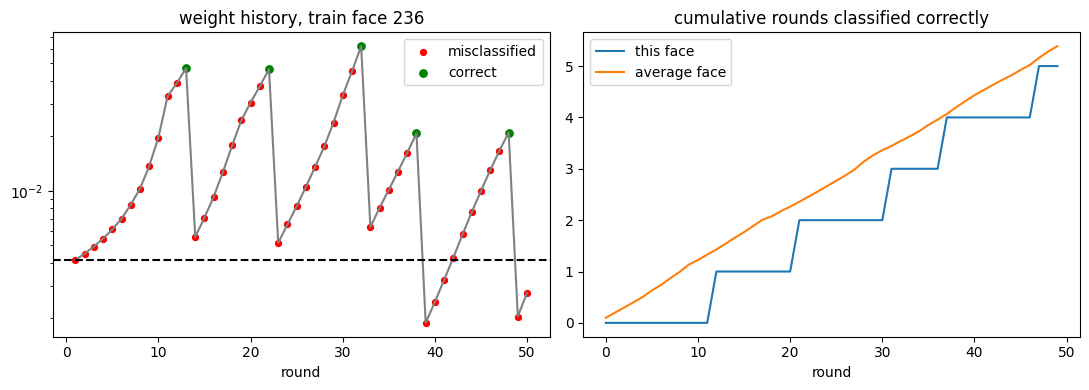

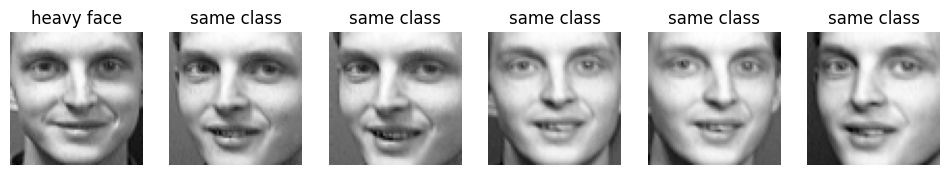

In [12]:
import time

def bag_fit(X, y, B, cfg, seed=digits):
    r = np.random.default_rng(seed)                # same stream as Step 3
    n, out = len(y), []
    for t in range(B):
        idx = r.integers(0, n, size=n)
        out.append(DecisionTreeClassifier(**{**cfg, "random_state": t}).fit(X[idx], y[idx]))
    return out

def bag_votes(ts, Xs):
    C = np.zeros((len(Xs), K))
    for m_ in ts:
        C[np.arange(len(Xs)), m_.predict(Xs)] += 1
    return C

def timed(fn, reps=3):
    secs = []
    for _ in range(reps):
        t0 = time.perf_counter(); out = fn(); secs.append(time.perf_counter() - t0)
    return out, float(np.median(secs))

sets = [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]
rows = []
for L in [25, 50, 100]:
    ts, t_bag = timed(lambda: bag_fit(X_train, y_train, L, tree_cfg))
    sc = {nm: (bag_votes(ts, Xs).argmax(1) == yy).mean() for nm, Xs, yy in sets}
    rows.append({"model": "bagging", "L": L, **sc, "time_s": t_bag})

    mb_, t_b = timed(lambda: samme_fit(X_train, y_train, K, b_depth, L))
    used = len(mb_["alphas"])
    sc = {nm: (samme_proba(mb_, Xs, used).argmax(1) == yy).mean() for nm, Xs, yy in sets}
    rows.append({"model": f"boosting d={b_depth}", "L": L, **sc, "time_s": t_b})

cmp_df = pd.DataFrame(rows)
print(cmp_df.round(3).to_string(index=False))

# ---------- heavy-weight training face (selected model) ----------
sel = boost_models[b_depth]; R = b_rounds
Wm = np.array(sel["W"][:R])                 # (R, N) weight used by learner t
Pm = np.array(sel["train_pred"][:R])        # (R, N) learner t's prediction
right = Pm == y_train
eps_t = np.array(sel["eps"][:R])

i = int(np.unravel_index(Wm.argmax(), Wm.shape)[1])   # face that reached the largest weight
print("heavy face idx", i, "| true class", y_train[i])
print("max weight", Wm[:, i].max().round(4), "| uniform", round(1 / len(y_train), 4))
print("learners right:", right[:, i].sum(), "of", R,
      "| average over all faces:", right.sum(0).mean().round(1))
print("most common wrong predictions:\n", pd.Series(Pm[~right[:, i], i]).value_counts().head(3))
q = samme_proba(sel, X_train[[i]], R)[0]
print("final q(true class) =", q[y_train[i]].round(3), "| final pred", q.argmax())

hist = pd.DataFrame({"round": np.arange(1, R + 1), "weight": Wm[:, i],
                     "pred": Pm[:, i], "correct": right[:, i], "eps": eps_t})
hist["ratio_next"] = np.r_[Wm[1:, i] / Wm[:-1, i], np.nan]
hist["ratio_expected"] = np.where(hist["correct"], 1 / (K * (1 - eps_t)),
                                  (K - 1) / (K * eps_t))
print(hist.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogy(hist["round"], hist["weight"], c="gray")
w_ = ~hist["correct"]
ax[0].scatter(hist["round"][w_], hist["weight"][w_], c="red", s=18, label="misclassified")
ax[0].scatter(hist["round"][~w_], hist["weight"][~w_], c="green", s=28, label="correct")
ax[0].axhline(1 / len(y_train), ls="--", c="k"); ax[0].legend()
ax[0].set_xlabel("round"); ax[0].set_title(f"weight history, train face {i}")
ax[1].plot(np.cumsum(right[:, i]), label="this face")
ax[1].plot(np.cumsum(right.mean(1)), label="average face")
ax[1].legend(); ax[1].set_xlabel("round"); ax[1].set_title("cumulative rounds classified correctly")
plt.tight_layout(); plt.savefig("q2c_history.png", dpi=150); plt.show()

same = [j for j in np.where(y_train == y_train[i])[0] if j != i]
fig, ax = plt.subplots(1, 6, figsize=(12, 2.4))
for a, j, t in zip(ax, [i] + same, ["heavy face"] + ["same class"] * 5):
    a.imshow(X_train[j].reshape(64, 64), cmap="gray"); a.set_title(t); a.axis("off")
plt.savefig("q2c_heavy_face.png", dpi=150); plt.show()

Q3

   model  clean_acc  mask_acc  clean_conf  mask_conf
    tree      0.600     0.275       0.994      0.975
 bagging      0.888     0.675       0.378      0.248
boosting      0.312     0.238       0.104      0.105
A: bag ok both, boost ok clean -> wrong masked -> [22 29 46 52 57 58 60]
B: boost ok both, bag ok clean -> wrong masked -> [68]
C: any face where bag_ok_masked != boost_ok_masked -> [ 1  4  5  7  9 11 12 13 14 15 16 20 21 22 23 24 27 29 31 34 35 36 42 43
 46 52 54 55 57 58 59 60 61 64 67 68 73 74 75 76 77]
using case A: bag ok both, boost ok clean -> wrong masked face 22
true class 11
[bag clean] pred 11 | true-class votes 12 | top [(11, 12), (9, 5), (13, 4)] | tree disagreement 0.921
[bag mask] pred 11 | true-class votes 7 | top [(11, 7), (13, 5), (37, 4)] | tree disagreement 0.949
[boost clean] pred 11 | q(true) 0.105 | max q 0.105
[boost mask] pred 13 | q(true) 0.078 | max q 0.084
boosting learners whose prediction changes: 6 of 50 | alpha share: 0.122
bagging trees whose pr

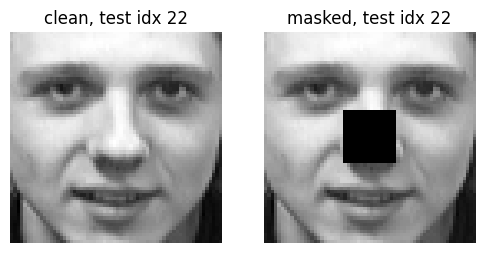

In [13]:
Rb, mb = b_rounds, boost_models[b_depth]

def in_mask(f):                       # feature index -> inside 24:40 x 24:40 block?
    r, c = f // 64, f % 64
    return (r >= 24) & (r < 40) & (c >= 24) & (c < 40)

def path_uses_mask(h, x):             # does this face's path touch a masked pixel?
    nodes = h.decision_path(x.reshape(1, -1)).indices
    f = h.tree_.feature[nodes]
    return bool(in_mask(f[f >= 0]).any())

# ---- accuracy + confidence on both sets ----
qc, qm = samme_proba(mb, X_test, Rb), samme_proba(mb, X_test_masked, Rb)
boost_pred = {"clean": qc.argmax(1), "mask": qm.argmax(1)}
boost_conf = {"clean": qc.max(1),    "mask": qm.max(1)}
bag_pred   = {"clean": Cc.argmax(1), "mask": Cm.argmax(1)}
bag_conf   = {"clean": Cc.max(1) / B_final, "mask": Cm.max(1) / B_final}
tree_pred  = {"clean": tree_clean_pred, "mask": tree_mask_pred}
tree_conf  = {"clean": tree_clean_conf, "mask": tree_mask_conf}

tab = pd.DataFrame([{
    "model": nm,
    "clean_acc": (P_["clean"] == y_test).mean(), "mask_acc": (P_["mask"] == y_test).mean(),
    "clean_conf": C_["clean"].mean(), "mask_conf": C_["mask"].mean()}
    for nm, P_, C_ in [("tree", tree_pred, tree_conf),
                       ("bagging", bag_pred, bag_conf),
                       ("boosting", boost_pred, boost_conf)]])
print(tab.round(3).to_string(index=False))

# ---- find a face where the two ensembles react differently ----
bc, bm = bag_pred["clean"] == y_test, bag_pred["mask"] == y_test
oc, om = boost_pred["clean"] == y_test, boost_pred["mask"] == y_test
cases = {
  "A: bag ok both, boost ok clean -> wrong masked": bc & bm & oc & ~om,
  "B: boost ok both, bag ok clean -> wrong masked": oc & om & bc & ~bm,
  "C: any face where bag_ok_masked != boost_ok_masked": (bm != om),
}
for k, v in cases.items(): print(k, "->", np.where(v)[0])
j = None
for k, v in cases.items():
    if v.any(): j = int(np.where(v)[0][0]); print("using case", k, "face", j); break

# ---- explain face j ----
xc, xm = X_test[j:j+1], X_test_masked[j:j+1]
tc = y_test[j]
print("true class", tc)
for nm, Cx in [("clean", Cc[j]), ("mask", Cm[j])]:
    dis = 1 - (Cx * (Cx - 1) / 2).sum() / (B_final * (B_final - 1) / 2)
    top = np.argsort(Cx)[::-1][:3]
    print(f"[bag {nm}] pred {Cx.argmax()} | true-class votes {int(Cx[tc])} "
          f"| top {[(int(k), int(Cx[k])) for k in top]} | tree disagreement {dis:.3f}")
for nm, q in [("clean", qc[j]), ("mask", qm[j])]:
    print(f"[boost {nm}] pred {q.argmax()} | q(true) {q[tc]:.3f} | max q {q.max():.3f}")

flip = [t for t in range(Rb) if mb["learners"][t].predict(xc)[0] != mb["learners"][t].predict(xm)[0]]
print("boosting learners whose prediction changes:", len(flip), "of", Rb,
      "| alpha share:", round(mb["alphas"][flip].sum() / mb["alphas"][:Rb].sum(), 3))
print("bagging trees whose prediction changes:",
      int((P["test"][:B_final, j] != P["mask"][:B_final, j]).sum()), "of", B_final)

# how many models' decision path for THIS face goes through the masked block
bag_path = np.mean([path_uses_mask(m_, X_test[j]) for m_ in trees[:B_final]])
bst_path = np.mean([path_uses_mask(h, X_test[j]) for h in mb["learners"][:Rb]])
print("fraction of paths using masked pixels | bagging:", round(bag_path, 3),
      "| boosting:", round(bst_path, 3), "| single tree:", path_uses_mask(tree, X_test[j]))

# boosting weight carried by this face's class in training
Wm = np.array(mb["W"][:Rb]); cls = y_train == tc
print("mean boosting weight per training face of class", tc, ":", Wm[:, cls].mean().round(5),
      "| overall mean:", round(1 / len(y_train), 5))

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
for a, Xs, t in zip(ax, (xc, xm), ("clean", "masked")):
    a.imshow(Xs.reshape(64, 64), cmap="gray"); a.axis("off"); a.set_title(f"{t}, test idx {j}")
plt.savefig("q2d_face.png", dpi=150); plt.show()

In [14]:
from joblib import Parallel, delayed

R = 30                     # first set R = 2 to time it
rs = np.random.default_rng([*digits, 3])
resamples = np.array([
    np.concatenate([rs.choice(np.where(y_train == k)[0], size=6, replace=True)
                    for k in range(K)]) for _ in range(R)])
np.save("q3_resamples.npy", resamples)

def bag_fit_par(X, y, B, cfg, seed):
    r = np.random.default_rng(seed); n = len(y)
    idxs = [r.integers(0, n, size=n) for _ in range(B)]       # serial, reproducible
    return Parallel(n_jobs=-1)(
        delayed(lambda i, t: DecisionTreeClassifier(**{**cfg, "random_state": t})
                .fit(X[i], y[i]))(i, t) for t, i in enumerate(idxs))

test_sets = {"clean": X_test, "mask": X_test_masked}
nT = len(y_test)
store = {m: {s: np.zeros((R, nT, K)) for s in test_sets} for m in ("tree", "bag", "boost")}

t0 = time.perf_counter()
for r in range(R):
    Xr, yr = X_train[resamples[r]], y_train[resamples[r]]
    t_ = DecisionTreeClassifier(**tree_cfg).fit(Xr, yr)
    bg = bag_fit_par(Xr, yr, B_final, tree_cfg, [*digits, 1, r])
    bt = samme_fit(Xr, yr, K, b_depth, b_rounds)
    used = len(bt["alphas"])
    for s, Xs in test_sets.items():
        store["tree"][s][r, np.arange(nT), t_.predict(Xs)] = 1
        store["bag"][s][r] = bag_votes(bg, Xs) / B_final
        store["boost"][s][r] = samme_proba(bt, Xs, used) if used > 0 else 0
    print(f"rep {r+1}/{R} done, {time.perf_counter()-t0:.0f}s elapsed")
np.savez("q3_probs.npz", **{f"{m}_{s}": store[m][s] for m in store for s in test_sets})

# ---------- bias^2, variance, accuracy ----------
E = np.eye(K)[y_test]
def bias_var(Pm):                                  # Pm: (R, N, K)
    pbar = Pm.mean(0)
    bias2 = ((pbar - E) ** 2).sum(1).mean()
    var = ((Pm - pbar) ** 2).sum(2).mean()
    mse = ((Pm - E) ** 2).sum(2).mean()
    return bias2, var, mse

rows = []
for m in ("tree", "bag", "boost"):
    Pm = store[m]["clean"]
    b2, v, mse = bias_var(Pm)
    accs = (Pm.argmax(2) == y_test).mean(1)
    macc = (store[m]["mask"].argmax(2) == y_test).mean(1)
    rows.append({"model": m, "bias2": b2, "variance": v, "bias2+var": b2 + v, "mse_check": mse,
                 "acc_mean": accs.mean(), "acc_std": accs.std(ddof=1),
                 "mask_acc_mean": macc.mean()})
q3a = pd.DataFrame(rows)
print(q3a.round(4).to_string(index=False))
print("tree check: 2*(1-mean acc) =", round(2 * (1 - q3a.loc[0, "acc_mean"]), 4))

rep 1/30 done, 10s elapsed
rep 2/30 done, 18s elapsed
rep 3/30 done, 27s elapsed
rep 4/30 done, 36s elapsed
rep 5/30 done, 45s elapsed
rep 6/30 done, 53s elapsed
rep 7/30 done, 62s elapsed
rep 8/30 done, 71s elapsed
rep 9/30 done, 80s elapsed
rep 10/30 done, 89s elapsed
rep 11/30 done, 97s elapsed
rep 12/30 done, 106s elapsed
rep 13/30 done, 115s elapsed
rep 14/30 done, 124s elapsed
rep 15/30 done, 133s elapsed
rep 16/30 done, 142s elapsed
rep 17/30 done, 151s elapsed
rep 18/30 done, 159s elapsed
rep 19/30 done, 168s elapsed
rep 20/30 done, 177s elapsed
rep 21/30 done, 186s elapsed
rep 22/30 done, 195s elapsed
rep 23/30 done, 204s elapsed
rep 24/30 done, 213s elapsed
rep 25/30 done, 222s elapsed
rep 26/30 done, 231s elapsed
rep 27/30 done, 240s elapsed
rep 28/30 done, 249s elapsed
rep 29/30 done, 258s elapsed
rep 30/30 done, 267s elapsed
model  bias2  variance  bias2+var  mse_check  acc_mean  acc_std  mask_acc_mean
 tree 0.4605    0.5770     1.0375     1.0375    0.4812   0.0425        

In [15]:
print("selected tree actual depth:", tree.get_depth(), "| leaves:", tree.get_n_leaves())

cfgs = {
    "shallow d=4": dict(max_depth=4,    min_samples_leaf=2),
    "mid d=16":    dict(max_depth=16,   min_samples_leaf=2),
    "selected":    dict(max_depth=None, min_samples_leaf=2),   # frozen, depth 38
}
R_run = 30
B100 = 100

def fit_bag_preds(Xr, yr, cfg, seed, Xte):
    r = np.random.default_rng(seed); n = len(yr)
    idxs = [r.integers(0, n, size=n) for _ in range(B100)]
    def one(i, t):
        m = DecisionTreeClassifier(**cfg, random_state=t).fit(Xr[i], yr[i])
        return m.predict(Xte), int((m.tree_.children_left == -1).sum())
    out = Parallel(n_jobs=-1)(delayed(one)(i, t) for t, i in enumerate(idxs))
    return np.array([o[0] for o in out]), np.mean([o[1] for o in out])

res = {}
for name, cfg in cfgs.items():
    Pt = np.zeros((R_run, nT, K)); Pb = np.zeros((R_run, nT, K))
    ls, dis, bl = [], [], []
    t0 = time.perf_counter()
    for r in range(R_run):
        Xr, yr = X_train[resamples[r]], y_train[resamples[r]]
        t_ = DecisionTreeClassifier(**cfg, random_state=0).fit(Xr, yr)
        ls.append(leaf_stats(t_))                       # (leaves, mean samples, frac single)
        Pt[r, np.arange(nT), t_.predict(X_test)] = 1
        preds, nl = fit_bag_preds(Xr, yr, cfg, [*digits, 5, r], X_test)
        C = votes(preds, B100)
        Pb[r] = C / B100
        dis.append(disagreement(C, B100)); bl.append(nl)
        print(f"{name}: rep {r+1}/{R_run}, {time.perf_counter()-t0:.0f}s")
    res[name] = dict(Pt=Pt, Pb=Pb, ls=np.array(ls), dis=np.mean(dis), bl=np.mean(bl))
    np.savez(f"q3b_{name.replace(' ', '_').replace('=', '')}.npz", Pt=Pt, Pb=Pb)   # progress saved
    print(name, "saved, shape", Pt.shape)               # must be (30, 80, 40)

rows = []
for name, d in res.items():
    b2t, vt, _ = bias_var(d["Pt"]); b2b, vb, _ = bias_var(d["Pb"])
    at = (d["Pt"].argmax(2) == y_test).mean(1); ab = (d["Pb"].argmax(2) == y_test).mean(1)
    rows.append({"setting": name,
        "tree_bias2": b2t, "tree_var": vt, "bag_bias2": b2b, "bag_var": vb,
        "var_removed": vt - vb, "pct_removed": 100 * (vt - vb) / vt,
        "tree_acc": at.mean(), "bag_acc": ab.mean(), "acc_gain": ab.mean() - at.mean(),
        "leaves": d["ls"][:, 0].mean(), "mean_samp_leaf": d["ls"][:, 1].mean(),
        "frac_single": d["ls"][:, 2].mean(),
        "bag_tree_leaves": d["bl"], "disagree": d["dis"]})
q3b = pd.DataFrame(rows)
print(q3b.round(3).T.to_string())

selected tree actual depth: 38 | leaves: 44
shallow d=4: rep 1/30, 1s
shallow d=4: rep 2/30, 2s
shallow d=4: rep 3/30, 4s
shallow d=4: rep 4/30, 5s
shallow d=4: rep 5/30, 6s
shallow d=4: rep 6/30, 7s
shallow d=4: rep 7/30, 8s
shallow d=4: rep 8/30, 10s
shallow d=4: rep 9/30, 11s
shallow d=4: rep 10/30, 13s
shallow d=4: rep 11/30, 14s
shallow d=4: rep 12/30, 15s
shallow d=4: rep 13/30, 17s
shallow d=4: rep 14/30, 18s
shallow d=4: rep 15/30, 20s
shallow d=4: rep 16/30, 21s
shallow d=4: rep 17/30, 22s
shallow d=4: rep 18/30, 24s
shallow d=4: rep 19/30, 25s
shallow d=4: rep 20/30, 26s
shallow d=4: rep 21/30, 28s
shallow d=4: rep 22/30, 29s
shallow d=4: rep 23/30, 31s
shallow d=4: rep 24/30, 32s
shallow d=4: rep 25/30, 33s
shallow d=4: rep 26/30, 35s
shallow d=4: rep 27/30, 36s
shallow d=4: rep 28/30, 38s
shallow d=4: rep 29/30, 39s
shallow d=4: rep 30/30, 40s
shallow d=4 saved, shape (30, 80, 40)
mid d=16: rep 1/30, 4s
mid d=16: rep 2/30, 8s
mid d=16: rep 3/30, 12s
mid d=16: rep 4/30, 16s


In [16]:
d = np.load("q3_probs.npz")
frozen = {"tree": (0.600, 0.275), "bag": (0.888, 0.675), "boost": (0.312, 0.238)}  # Step 8

rows = []
for m in ("tree", "bag", "boost"):
    Pc, Pm = d[f"{m}_clean"], d[f"{m}_mask"]
    b2c, vc, _ = bias_var(Pc)
    b2m, vm, _ = bias_var(Pm)
    ac = (Pc.argmax(2) == y_test).mean(1)
    am = (Pm.argmax(2) == y_test).mean(1)
    rows.append({"model": m,
        "clean_acc": ac.mean(), "mask_acc": am.mean(),
        "drop": ac.mean() - am.mean(), "rel_drop": (ac.mean() - am.mean()) / ac.mean(),
        "bias2": b2c, "variance": vc,
        "bias2_mask": b2m, "var_mask": vm,
        "frozen_clean": frozen[m][0], "frozen_mask": frozen[m][1]})
final = pd.DataFrame(rows)
print(final.round(3).to_string(index=False))
final.to_csv("q3d_final_table.csv", index=False)

model  clean_acc  mask_acc  drop  rel_drop  bias2  variance  bias2_mask  var_mask  frozen_clean  frozen_mask
 tree      0.481     0.369 0.112     0.234  0.460     0.577       0.605     0.657         0.600        0.275
  bag      0.739     0.576 0.163     0.220  0.506     0.032       0.675     0.032         0.888        0.675
boost      0.160     0.140 0.019     0.120  0.917     0.016       0.920     0.019         0.312        0.238
